In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]

import json
import sys

import matplotlib.pyplot as plt
import numpy as np
sys.path.insert(0, "../../../skills/academic-figure/assets")  # the skill's style files
import paper  # registers the bundled Inter font
from paper import fit_height, mark_value, smooth, darken, lighten

colors = paper.use_design("../../../skills/academic-figure/assets/DESIGN.md")  # the style from DESIGN.md's tokens; colors["series-1"], colors["ours"], …

## learning-curve

**Figure 1: Validation accuracy on CIFAR-100 over training for our augmentation, Mixup and the baseline.** Lines show the mean and shaded bands ±1 std over 5 seeds; dashed horizontal lines mark the final mean accuracy of ours and of the baseline. Ours converges to 91.2% at epoch 50, 1.7 points above Mixup (89.5%) and 3.5 above the baseline (87.8%), and its worst seed (90.5%) still ends above the best Mixup seed (90.3%).

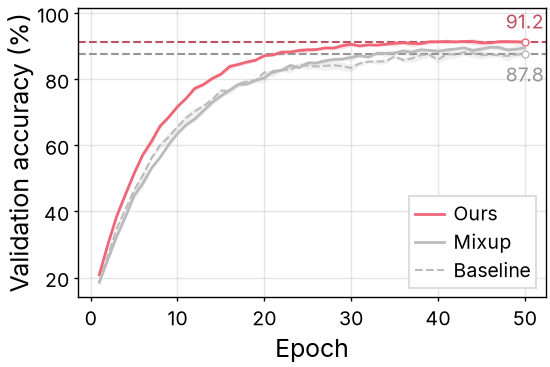

In [2]:
with open("../data/learning-curve.json") as f:
    data = json.load(f)
epochs = np.array(data["epochs"])

fig, ax = plt.subplots(figsize=(2.75, 2))
styles = {
    "Ours": dict(color=colors["ours"], linestyle="-", linewidth=None),
    "Mixup": dict(color=colors["neutral"], linestyle="-", linewidth=None),
    "Baseline": dict(color=colors["neutral"], linestyle="--", linewidth=paper.dashed_width),
}
for method, style in styles.items():
    runs = np.array(data["accuracy"][method]) * 100
    mean, std = runs.mean(axis=0), runs.std(axis=0)
    ax.plot(epochs, mean, label=method, **style)
    ax.fill_between(epochs, mean - std, mean + std, color=style["color"], alpha=0.2, linewidth=0)
    # the three final means lie within 3.5 points on a 20-95 axis, so only the outer two fit a label
    if method == "Ours":
        mark_value(ax, epochs[-1], mean[-1], f"{mean[-1]:.1f}", style["color"])
    if method == "Baseline":
        mark_value(ax, epochs[-1], mean[-1], f"{mean[-1]:.1f}", style["color"], below=True)

ax.set_xlabel("Epoch")
ax.set_ylabel("Validation accuracy (%)")
ax.legend(loc="lower right")
fit_height(fig, ax, aspect=0.618)
fig.savefig("../outputs/learning-curve.pdf")
fig.savefig("../outputs/learning-curve.png")
plt.show()